In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

from mlxtend.plotting import plot_decision_regions

import warnings
warnings.filterwarnings('ignore')

In [117]:
data = load_iris()
df = pd.DataFrame(data.data, columns = data.feature_names)
df['species'] = data.target

In [118]:
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

In [119]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [120]:
df.shape

(150, 5)

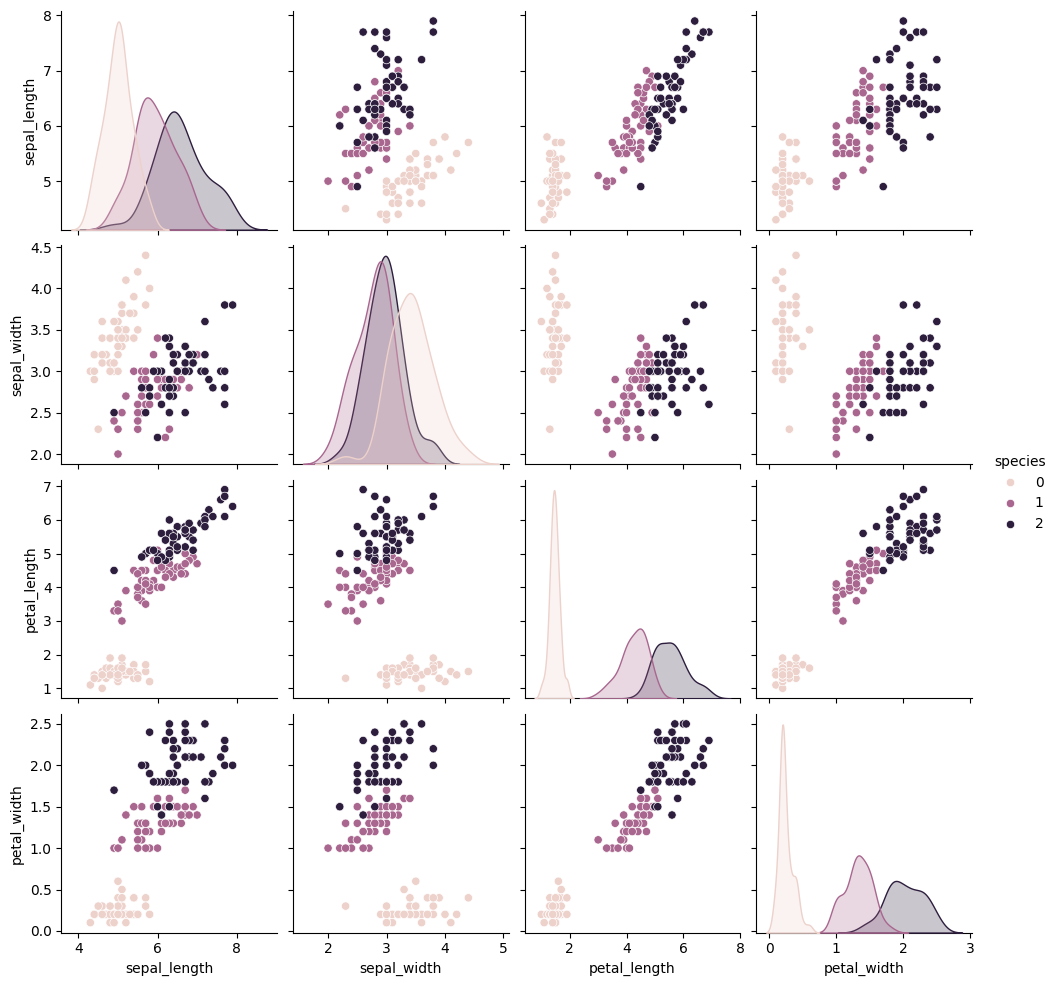

In [121]:
sns.pairplot(df, hue = 'species')

In [122]:
df = df[df['species'] != 0][['sepal_width', 'petal_length', 'species']]
df.sample(5)

,sepal_width,petal_length,species
86,3.1,4.7,1
93,2.3,3.3,1
81,2.4,3.7,1
146,2.5,5.0,2
145,3.0,5.2,2


In [123]:
df.shape

(100, 3)

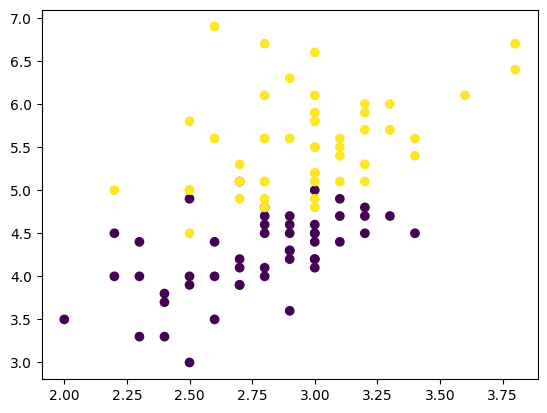

In [124]:
plt.scatter(df['sepal_width'], df['petal_length'], c=df['species'], cmap='viridis')
plt.show()

In [125]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [126]:
df_train

,sepal_width,petal_length,species
95,3.0,4.2,1
64,2.9,3.6,1
105,3.0,6.6,2
128,2.8,5.6,2
85,3.4,4.5,1
112,3.0,5.5,2
82,2.7,3.9,1
59,2.7,3.9,1
98,2.5,3.0,1
131,3.8,6.4,2


In [127]:
df_val

,sepal_width,petal_length,species
127,3.0,4.9,2
63,2.9,4.7,1
87,2.3,4.4,1
90,2.6,4.4,1
111,2.7,5.3,2


In [128]:
df_test

,sepal_width,petal_length,species
69,2.5,3.9,1
70,3.2,4.8,1
66,3.0,4.5,1
74,2.9,4.3,1
141,3.1,5.1,2


In [129]:
X_test = df_val.drop(columns = ['species'])
y_test = df_val.species

In [130]:
y_test

127    2
63     1
87     1
90     1
111    2
Name: species, dtype: int64

# Case 1- Bagging

In [131]:
# Data for Tree 1
df_bag = df_train.sample(8, replace = True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

In [132]:
df_bag

,sepal_width,petal_length,species
131,3.8,6.4,2
82,2.7,3.9,1
105,3.0,6.6,2
59,2.7,3.9,1
98,2.5,3.0,1
105,3.0,6.6,2
131,3.8,6.4,2
82,2.7,3.9,1


In [133]:
X

,sepal_width,petal_length
131,3.8,6.4
82,2.7,3.9
105,3.0,6.6
59,2.7,3.9
98,2.5,3.0
105,3.0,6.6
131,3.8,6.4
82,2.7,3.9


In [134]:
y

131    2
82     1
105    2
59     1
98     1
105    2
131    2
82     1
Name: species, dtype: int64

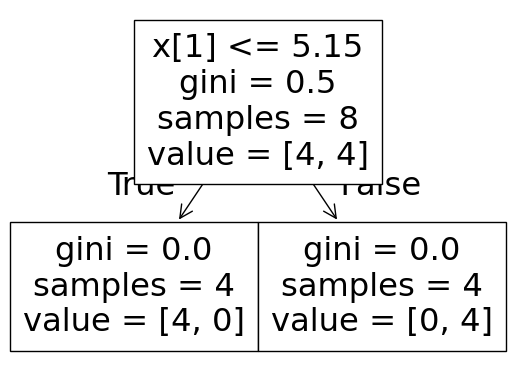

0.8


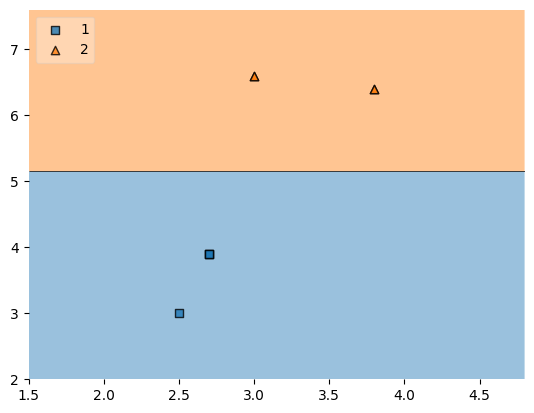

In [135]:
dt_bag1 = DecisionTreeClassifier()
evaluate(dt_bag1,X,y)

In [136]:
def evaluate(clf, X, y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values,y.values, clf = clf, legend = 2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test, y_pred))
    

In [137]:
# Data for Tree 2
df_bag2 = df_train.sample(8, replace=True)

X = df_bag2.drop(columns = ['species'])
y = df_bag2.species

df_bag2

,sepal_width,petal_length,species
64,2.9,3.6,1
98,2.5,3.0,1
98,2.5,3.0,1
105,3.0,6.6,2
112,3.0,5.5,2
64,2.9,3.6,1
131,3.8,6.4,2
98,2.5,3.0,1


In [138]:
X

,sepal_width,petal_length
64,2.9,3.6
98,2.5,3.0
98,2.5,3.0
105,3.0,6.6
112,3.0,5.5
64,2.9,3.6
131,3.8,6.4
98,2.5,3.0


In [139]:
y

64     1
98     1
98     1
105    2
112    2
64     1
131    2
98     1
Name: species, dtype: int64

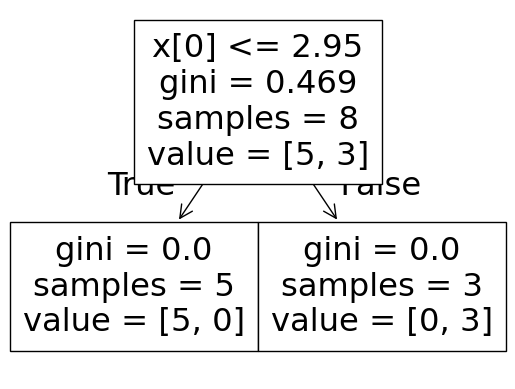

0.8


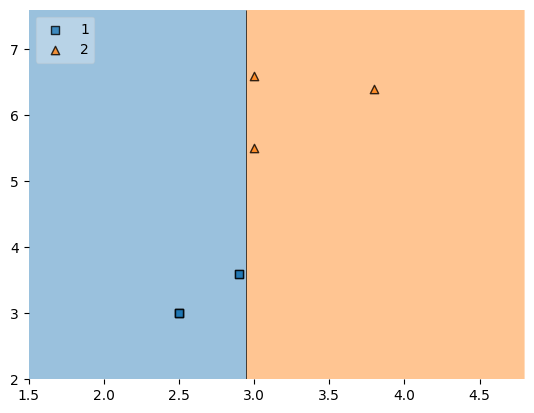

In [140]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2, X,y)

In [141]:
# Data for Tree 3
df_bag3 = df_train.sample(8,replace = True)

X = df_bag3.drop(columns = 'species')
y = df_bag3.species

df_bag3

,sepal_width,petal_length,species
85,3.4,4.5,1
59,2.7,3.9,1
128,2.8,5.6,2
82,2.7,3.9,1
59,2.7,3.9,1
95,3.0,4.2,1
131,3.8,6.4,2
64,2.9,3.6,1


In [142]:
X

,sepal_width,petal_length
85,3.4,4.5
59,2.7,3.9
128,2.8,5.6
82,2.7,3.9
59,2.7,3.9
95,3.0,4.2
131,3.8,6.4
64,2.9,3.6


In [143]:
y

85     1
59     1
128    2
82     1
59     1
95     1
131    2
64     1
Name: species, dtype: int64

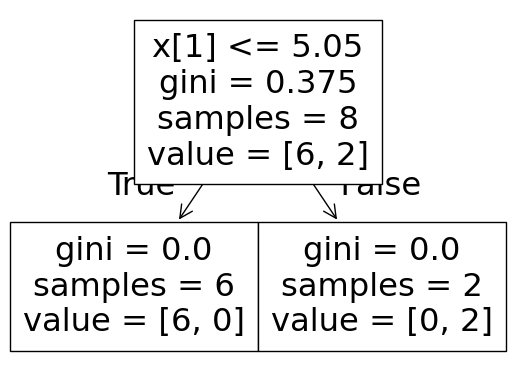

0.8


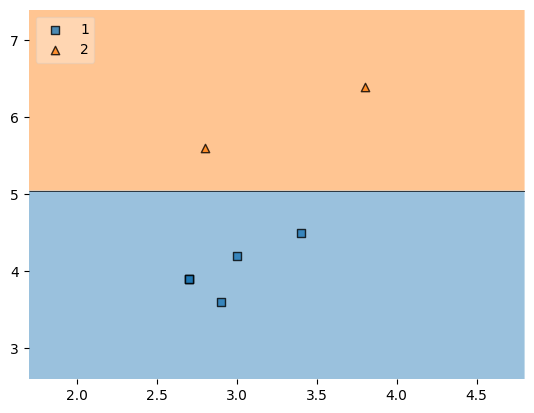

In [144]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [148]:
df_test

,sepal_width,petal_length,species
69,2.5,3.9,1
70,3.2,4.8,1
66,3.0,4.5,1
74,2.9,4.3,1
141,3.1,5.1,2


# Predict

In [147]:
print(f"Predictor 1 -> {dt_bag1.predict(np.array([2.9,4.3]).reshape(1,2))}")
print(f"Predictor 2 -> {dt_bag2.predict(np.array([2.9,4.3]).reshape(1,2))}")
print(f"Predictor 3 -> {dt_bag3.predict(np.array([2.9,4.3]).reshape(1,2))}")

Predictor 1 -> [1]
Predictor 2 -> [1]
Predictor 3 -> [1]


# Pasting

* Only difference with **bagging** &rarr; sampling without *replacement*

In [149]:
df_train

,sepal_width,petal_length,species
95,3.0,4.2,1
64,2.9,3.6,1
105,3.0,6.6,2
128,2.8,5.6,2
85,3.4,4.5,1
112,3.0,5.5,2
82,2.7,3.9,1
59,2.7,3.9,1
98,2.5,3.0,1
131,3.8,6.4,2


In [151]:
df_bag = df_train.sample(10)
X=df_bag.drop(columns = 'species')
y=df_bag.species

In [152]:
X

,sepal_width,petal_length
64,2.9,3.6
95,3.0,4.2
98,2.5,3.0
82,2.7,3.9
59,2.7,3.9
105,3.0,6.6
131,3.8,6.4
112,3.0,5.5
85,3.4,4.5
128,2.8,5.6


In [153]:
y

64     1
95     1
98     1
82     1
59     1
105    2
131    2
112    2
85     1
128    2
Name: species, dtype: int64

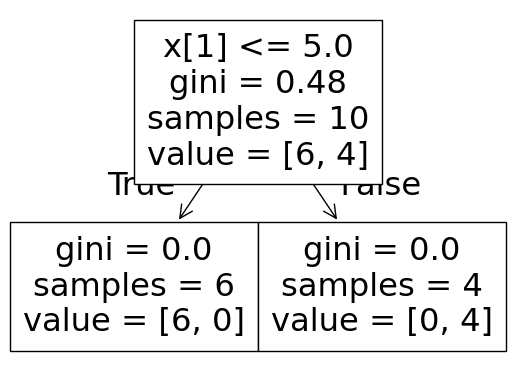

0.8


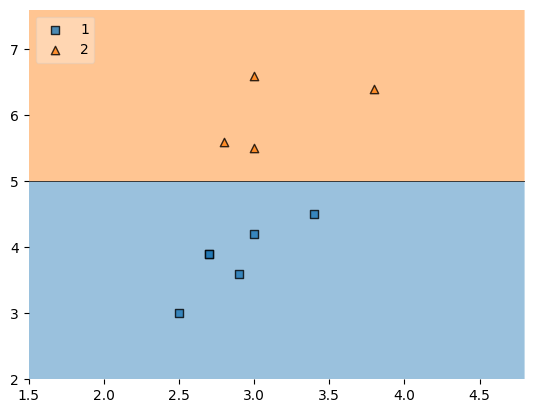

In [154]:
dt_bag = DecisionTreeClassifier()
evaluate(dt_bag,X,y)

# Random Subpaces

* only difference with **bagging** &rarr; sampling *columns* instead of *rows*&rarr; with + without replacement

In [157]:
df1 = df.copy()
df1 = df1.sample(10)
df1

,sepal_width,petal_length,species
116,3.0,5.5,2
61,3.0,4.2,1
124,3.3,5.7,2
99,2.8,4.1,1
129,3.0,5.8,2
128,2.8,5.6,2
59,2.7,3.9,1
55,2.8,4.5,1
118,2.6,6.9,2
56,3.3,4.7,1


In [175]:
df1.sample(2, replace = False, axis =1)

,petal_length,sepal_width
116,5.5,3.0
61,4.2,3.0
124,5.7,3.3
99,4.1,2.8
129,5.8,3.0
128,5.6,2.8
59,3.9,2.7
55,4.5,2.8
118,6.9,2.6
56,4.7,3.3


In [159]:
df_bag = df1.sample(10)
X=df_bag.drop(columns = 'species')
y=df_bag.species

In [162]:
X

,sepal_width,petal_length
59,2.7,3.9
128,2.8,5.6
56,3.3,4.7
124,3.3,5.7
61,3.0,4.2
55,2.8,4.5
118,2.6,6.9
116,3.0,5.5
99,2.8,4.1
129,3.0,5.8


In [164]:
X_subs = X.sample(1,replace = False, axis = 1)
X_subs

,petal_length
59,3.9
128,5.6
56,4.7
124,5.7
61,4.2
55,4.5
118,6.9
116,5.5
99,4.1
129,5.8


# Random Patches

* **rows + columns** sampling

In [182]:
data = load_iris()
df = pd.DataFrame(data.data, columns = data.feature_names)
df['species'] = data.target

In [185]:
df.sample(8, replace = True).sample(3, replace = True, axis = 1)

,petal width (cm),petal width (cm),sepal length (cm)
51,1.5,1.5,6.4
6,0.3,0.3,4.6
34,0.2,0.2,4.9
105,2.1,2.1,7.6
26,0.4,0.4,5.0
58,1.3,1.3,6.6
124,2.1,2.1,6.7
72,1.5,1.5,6.3
